# House-price CNN project — streamlined notebook scaffold

This notebook contains the **essential code workflow**, not a complete implementation. Complete each `TODO` in order. It keeps only the comparisons needed to answer the proposal:

1. Standard VGG16 spatial representation.
2. VGG16 with global average pooling (GAP).
3. GAP plus mask-guided house, surroundings, and background features.
4. The same regional model with photometric augmentation.

Removed from the longer version: extensive dataset auditing, a separate mask-statistics study, parameter-count experiments, a five-level lighting sweep, and detailed residual/error-case testing.

## 1. Imports and fixed settings

All experiments must use the same split, VGG16 weights, optimiser settings, loss, and evaluation metrics. Only the representation or augmentation condition should change. Update the three dataset column names after inspecting your metadata file.

In [26]:
%pip install torch torchvision transformers

Note: you may need to restart the kernel to use updated packages.


In [130]:
from pathlib import Path
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from transformers import (
    AutoImageProcessor,
    SegformerForSemanticSegmentation
)

from tqdm import tqdm


CONFIG = {
    "seed": 48,

    "id_column": "imageid",
    "target_column": "price",
    "image_column": "image_path",

    "image_size": 224,
    "batch_size": 32,
    "num_workers": 0,

    "train_fraction": 0.70,
    "validation_fraction": 0.15,
    "test_fraction": 0.15,

    "epochs": 20,
    "learning_rate_backbone": 1e-5,
    "early_stopping_patience": 4,
}

E2_CONFIG = {
    "model_name": "model_e2_global_average_pooling",
    "projection_dim": 128,
    "dropout": 0.30,
    "learning_rate_head": 1e-3,
    "weight_decay": 1e-4,
}


E3_CONFIG = {
    "model_name": "model_e3_refined_regional_fusion",
    "projection_dim": 64,
    "dropout": 0.50,
    "learning_rate_head": 3e-4,
    "weight_decay": 1e-3,
}


MASK_CONFIG = {
    "segmentation_model":
        "nvidia/segformer-b0-finetuned-ade-512-512",

    "surroundings_dilation_pixels": 32,
}

PATHS = {
    "train_csv": Path("house_dataset/train.csv"),
    "test_csv": Path("house_dataset/test.csv"),
    "sample_solution": Path(
        "house_dataset/sample_solution.csv"
    ),

    "train_images": Path("house_dataset/train"),
    "test_images": Path("house_dataset/test"),

    "splits": Path("artifacts/splits"),
    "masks": Path("artifacts/masks"),
    "checkpoints": Path("artifacts/checkpoints"),
    "results": Path("artifacts/results"),
}

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif (hasattr(torch.backends, "mps") and torch.backends.mps.is_available()):
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")



def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed(CONFIG["seed"])

for key in ["splits", "masks", "checkpoints", "results"]:
    PATHS[key].mkdir(parents=True, exist_ok=True)

## 2. Load metadata and create one fixed split

Perform only essential checks: required columns, positive prices, existing image files, and no property overlap between splits. If a property has several photographs, all its photographs must remain in one split. Save the split CSV files and reuse them in every experiment.

In [133]:
# Load CSV files
train_df = pd.read_csv(
    PATHS["train_csv"],
    dtype={"imageid": str}
)

test_df = pd.read_csv(
    PATHS["test_csv"],
    dtype={"imageid": str}
)

sample_solution_df = pd.read_csv(
    PATHS["sample_solution"],
    dtype={"imageid": str}
)

ID_COLUMN = CONFIG["id_column"]
TARGET_COLUMN = CONFIG["target_column"]
IMAGE_COLUMN = CONFIG["image_column"]

train_df[IMAGE_COLUMN] = train_df[ID_COLUMN].apply(
    lambda filename:
        PATHS["train_images"] / filename
)

test_df[IMAGE_COLUMN] = test_df[ID_COLUMN].apply(
    lambda filename:
        PATHS["test_images"] / filename
)

In [135]:
# Confirm that the requested fractions add up to 100%
total_fraction = (
    CONFIG["train_fraction"]
    + CONFIG["validation_fraction"]
    + CONFIG["test_fraction"]
)

assert np.isclose(total_fraction, 1.0), (
    "train_fraction, validation_fraction, and test_fraction "
    "must add up to 1.0."
)


development_df, internal_test_df = train_test_split(
    train_df,
    test_size=CONFIG["test_fraction"],
    random_state=CONFIG["seed"],
    shuffle=True
)


# The validation fraction must be calculated relative to the
# remaining development data.
validation_share_of_development = (
    CONFIG["validation_fraction"]
    / (
        CONFIG["train_fraction"]
        + CONFIG["validation_fraction"]
    )
)

train_split_df, validation_df = train_test_split(
    development_df,
    test_size=validation_share_of_development,
    random_state=CONFIG["seed"],
    shuffle=True
)

train_split_df = train_split_df.reset_index(drop=True)
validation_df = validation_df.reset_index(drop=True)
internal_test_df = internal_test_df.reset_index(drop=True)

train_ids = set(train_split_df[CONFIG["id_column"]])
validation_ids = set(validation_df[CONFIG["id_column"]])
internal_test_ids = set(internal_test_df[CONFIG["id_column"]])

assert train_ids.isdisjoint(validation_ids)
assert train_ids.isdisjoint(internal_test_ids)
assert validation_ids.isdisjoint(internal_test_ids)

assert (
    len(train_split_df)
    + len(validation_df)
    + len(internal_test_df)
    == len(train_df)
)


train_split_df.to_csv(
    PATHS["splits"] / "train_split.csv",
    index=False
)

validation_df.to_csv(
    PATHS["splits"] / "validation_split.csv",
    index=False
)

internal_test_df.to_csv(
    PATHS["splits"] / "internal_test_split.csv",
    index=False
)

TARGET_MEAN = float(
    train_split_df[CONFIG["target_column"]].mean()
)

TARGET_STD = float(
    train_split_df[CONFIG["target_column"]].std()
)

print(train_split_df.shape)
print(validation_df.shape)
print(internal_test_df.shape)
print(TARGET_MEAN, TARGET_STD)

(5600, 3)
(1200, 3)
(1200, 3)
721.7907048214286 395.00169466521675


## 3. Image transformations

Use ordinary ImageNet preprocessing for E1–E3. Add colour and lighting jitter only for E4. Validation and test transforms must be deterministic. When implementing the dataset, make sure random resizing/flipping is shared by the image and masks, while colour jitter is applied only to the image.

In [138]:
# Normalization values used when VGG16 was trained on ImageNet
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]


standard_train_transform = transforms.Compose([
    transforms.Resize(
        (CONFIG["image_size"], CONFIG["image_size"])
    ),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

evaluation_transform = transforms.Compose([
    transforms.Resize((CONFIG["image_size"], CONFIG["image_size"])),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])


## 4. Dataset and DataLoaders

Return the image, price, property ID, and—only when requested—the three masks. Use `log1p(price)` during training if configured, then transform predictions back with `expm1` before calculating metrics.

In [141]:
class HousePriceDataset(Dataset):
    """
    Connects each house image with its corresponding price.

    Each returned sample contains:
        image: processed image tensor
        target: house price or log-transformed house price
        image_id: filename of the image
    """

    def __init__(self, dataframe, transform):
        self.dataframe = dataframe.reset_index(drop=True).copy()
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        # Select one row from the DataFrame
        row = self.dataframe.iloc[index]

        # Read the image
        image_path = row[CONFIG["image_column"]]
        image = Image.open(image_path).convert("RGB")

        # Apply resizing, tensor conversion and normalization
        image = self.transform(image)

        # Read the corresponding house price
        price = float(row[CONFIG["target_column"]])
        
        standardized_price = (price - TARGET_MEAN) / TARGET_STD
        
        target = torch.tensor(standardized_price, dtype=torch.float32)

        image_id = str(row[CONFIG["id_column"]])

        return {
            "image": image,
            "target": target,
            "image_id": image_id
        }

## 6. Train and evaluate Pipeline

In [144]:
def forward_batch(model, batch, device):
    images = batch["image"].to(device)

    if "masks" in batch:
        masks = batch["masks"].to(device)
        return model(images, masks)

    return model(images)


def train_one_epoch(model, data_loader, optimizer, criterion, device):
    model.train()

    total_loss = 0.0
    total_samples = 0

    progress_bar = tqdm(data_loader, desc="Training", leave=False)

    for batch in progress_bar:
        targets = batch["target"].to(device)
        optimizer.zero_grad()
        predictions = forward_batch(model, batch, device)
        loss = criterion(predictions, targets)
        loss.backward()
        optimizer.step()
        batch_size = targets.size(0)
        total_loss += loss.item() * batch_size
        total_samples += batch_size
        progress_bar.set_postfix(loss=f"{total_loss / total_samples:.4f}")

    return total_loss / total_samples


def evaluate_model(model, data_loader, criterion, device):
    model.eval()

    total_loss = 0.0
    total_samples = 0

    predicted_targets = []
    true_targets = []

    progress_bar = tqdm(data_loader, desc="Validation", leave=False)


    with torch.no_grad():
        for batch in progress_bar:
            targets = batch["target"].to(device)

            predictions = forward_batch(model, batch, device)
            loss = criterion(predictions, targets)

            batch_size = targets.size(0)
            total_loss += loss.item() * batch_size
            total_samples += batch_size

            predicted_targets.append(predictions.cpu())
            true_targets.append(targets.cpu())
            progress_bar.set_postfix(loss=f"{total_loss / total_samples:.4f}")

    predicted_targets = torch.cat(predicted_targets).numpy()
    true_targets = torch.cat(true_targets).numpy()

    # Convert standardized targets back to original prices
    predicted_prices = (predicted_targets * TARGET_STD + TARGET_MEAN)
    
    true_prices = (true_targets * TARGET_STD + TARGET_MEAN)

    # A house price should not be negative
    predicted_prices = np.maximum(predicted_prices, 0)

    mse = mean_squared_error(true_prices, predicted_prices)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(true_prices, predicted_prices)
    r2 = r2_score(true_prices, predicted_prices)

    return {
        "loss": total_loss / total_samples,
        "mse": mse,
        "rmse": rmse,
        "mae": mae,
        "r2": r2
    }


def create_optimizer(model, experiment_config):
    
    backbone_parameters = [
        parameter
        for parameter in model.backbone.parameters()
        if parameter.requires_grad
    ]
    
    backbone_parameter_ids = {id(parameter) for parameter in model.backbone.parameters()}
    head_parameters = [
        parameter
        for parameter in model.parameters()
        if parameter.requires_grad and id(parameter) not in backbone_parameter_ids
    ]

    backbone_group = {
        "params": backbone_parameters,
        "lr": CONFIG["learning_rate_backbone"]
    }

    head_group = {
        "params": head_parameters,
        "lr": experiment_config["learning_rate_head"]
    }

    parameter_groups = [
        backbone_group,
        head_group
    ]

    optimizer = torch.optim.AdamW(
        params=parameter_groups,
        weight_decay=experiment_config["weight_decay"]
    )

    return optimizer


def fit_model(model, train_loader, validation_loader, experiment_config, device=DEVICE):
    model_name = experiment_config["model_name"]
    model = model.to(device)
    criterion = nn.MSELoss()
    optimizer = create_optimizer(model, experiment_config)
    checkpoint_path = PATHS["checkpoints"] / f"{model_name}.pt"
    history_path = PATHS["results"] / f"{model_name}_training_history.csv"

    history = []
    best_validation_mse = float("inf")
    epochs_without_improvement = 0

    for epoch in range(1, CONFIG["epochs"] + 1):
        training_loss = train_one_epoch(
            model, train_loader, optimizer, criterion, device
        )
        
        validation_metrics = evaluate_model(
            model, validation_loader, criterion, device
        )

        history.append({
            "epoch": epoch,
            "training_loss": training_loss,
            **{f"validation_{key}": value for key, value in validation_metrics.items()}
        })

        print(
            f"{model_name} | Epoch {epoch:02d}/{CONFIG['epochs']} | "
            f"MSE: {validation_metrics['mse']:.4f} | "
            f"RMSE: {validation_metrics['rmse']:.4f} | "
            f"MAE: {validation_metrics['mae']:.4f} | "
            f"R²: {validation_metrics['r2']:.4f}"
        )

        if validation_metrics["mse"] < best_validation_mse:
            best_validation_mse = float(validation_metrics["mse"])
            epochs_without_improvement = 0
            torch.save({
                "epoch": int(epoch),
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "validation_mse": best_validation_mse,
                "target_mean": float(TARGET_MEAN),
                "target_std": float(TARGET_STD),
                "target_method": "standardization",
                "loss_function": criterion.__class__.__name__,
                "model_name": model_name
            }, checkpoint_path)
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= CONFIG["early_stopping_patience"]:
            break

    checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=True)
    model.load_state_dict(checkpoint["model_state_dict"])
    best_metrics = evaluate_model(model, validation_loader, criterion, device)

    history_df = pd.DataFrame(history)
    history_df.to_csv(history_path, index=False)

    summary = {
        "model": model_name,
        "best_epoch": checkpoint["epoch"],
        **{f"validation_{key}": value for key, value in best_metrics.items()},
        "checkpoint": str(checkpoint_path)
    }
    return model, history_df, summary

### Reusing the pipeline for E2–E3

Each model uses `fit_model`; supply the loader that matches its inputs. E1 and E2 use image-only loaders. E3 and E4 use loaders that also return a `masks` tensor.

```python
# E2: model_e2, history_e2_df, summary_e2 = fit_model(
#     model_e2, standard_train_loader, validation_loader, "model_e2_global_pooling"
# )

# E3: model_e3, history_e3_df, summary_e3 = fit_model(
#     model_e3, masked_train_loader, masked_validation_loader, "model_e3_masked_regions"
# )

```

In [151]:
class GlobalAveragePoolingRegressor(nn.Module):

    def __init__(self, projection_dim=128, dropout=0.30):
        super().__init__()

        # Load the same pretrained VGG16 used by E1
        vgg16 = models.vgg16(
            weights=models.VGG16_Weights.IMAGENET1K_V1
        )

        self.backbone = vgg16.features

        # Freeze the complete backbone
        for parameter in self.backbone.parameters():
            parameter.requires_grad = False

        # Fine-tune the final seven backbone layers
        for parameter in self.backbone[-7:].parameters():
            parameter.requires_grad = True

        # Convert [B, 512, 7, 7] into [B, 512, 1, 1]
        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))

        # Convert the 512 global features into one predicted value
        self.regression_head = nn.Sequential(
            nn.Flatten(),
            nn.Linear(512, projection_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(projection_dim, 1)
        )

    def forward(self, images):

        # Extract CNN feature maps
        feature_maps = self.backbone(images)

        # Average each channel over all spatial positions
        global_features = self.global_pool(feature_maps)

        # Predict the standardized house price
        predictions = self.regression_head(global_features)

        return predictions.squeeze(1)


set_seed(CONFIG["seed"])

model_e2 = GlobalAveragePoolingRegressor(
    projection_dim=E2_CONFIG["projection_dim"],
    dropout=E2_CONFIG["dropout"]
).to(DEVICE)

In [17]:
e2_train_dataset = HousePriceDataset(
    dataframe=train_split_df,
    transform=standard_train_transform
)

e2_validation_dataset = HousePriceDataset(
    dataframe=validation_df,
    transform=evaluation_transform
)

e2_train_loader = DataLoader(
    e2_train_dataset,
    batch_size=CONFIG["batch_size"],
    shuffle=True,
    num_workers=CONFIG["num_workers"],
    pin_memory=torch.cuda.is_available()
)

e2_validation_loader = DataLoader(
    e2_validation_dataset,
    batch_size=CONFIG["batch_size"],
    shuffle=False,
    num_workers=CONFIG["num_workers"],
    pin_memory=torch.cuda.is_available()
)

model_e2, history_e2_df, summary_e2 = fit_model(
    model=model_e2,
    train_loader=e2_train_loader,
    validation_loader=e2_validation_loader,
    experiment_config=E2_CONFIG,
    device=DEVICE
)

pd.DataFrame([summary_e2])

model_e2_global_average_pooling | Epoch 01/20 | MSE: 122522.3984 | RMSE: 350.0320 | MAE: 273.3254 | R²: 0.2024


model_e2_global_average_pooling | Epoch 02/20 | MSE: 119709.6250 | RMSE: 345.9908 | MAE: 251.3578 | R²: 0.2208


model_e2_global_average_pooling | Epoch 03/20 | MSE: 118890.4531 | RMSE: 344.8050 | MAE: 267.8573 | R²: 0.2261


model_e2_global_average_pooling | Epoch 04/20 | MSE: 117959.7578 | RMSE: 343.4527 | MAE: 259.2338 | R²: 0.2321


model_e2_global_average_pooling | Epoch 05/20 | MSE: 118480.6172 | RMSE: 344.2101 | MAE: 259.8282 | R²: 0.2288


model_e2_global_average_pooling | Epoch 06/20 | MSE: 121990.7734 | RMSE: 349.2718 | MAE: 256.9309 | R²: 0.2059


model_e2_global_average_pooling | Epoch 07/20 | MSE: 126662.1562 | RMSE: 355.8963 | MAE: 264.6128 | R²: 0.1755


model_e2_global_average_pooling | Epoch 08/20 | MSE: 130646.1328 | RMSE: 361.4500 | MAE: 267.0676 | R²: 0.1496


,model,best_epoch,validation_loss,validation_mse,validation_rmse,validation_mae,validation_r2,checkpoint
0,model_e2_global_average_pooling,4,0.756025,117959.757812,343.452698,259.233826,0.232144,artifacts\checkpoints\model_e2_global_average_...


## 8. Region masks fused with global pooling

Generate house, surroundings, and background masks once, then train the regional model with the existing `fit_model` pipeline. Skip the E1 and E2 training cells on a fresh kernel. Run the configuration, split, transform, `HousePriceDataset`, and `fit_model` cells first.

In [161]:
HOUSE_CLASS_IDS = (0, 1, 8, 14, 25)  # wall, building, windowpane, door, house

processor = AutoImageProcessor.from_pretrained(MASK_CONFIG["segmentation_model"])
seg_model = SegformerForSemanticSegmentation.from_pretrained(MASK_CONFIG["segmentation_model"]).to(DEVICE).eval()


def labels_to_masks(labels):
    """Turn class ids into house, surroundings, and background masks."""
    house = torch.zeros_like(labels, dtype=torch.float32)
    for class_id in HOUSE_CLASS_IDS:
        house = torch.maximum(house, (labels == class_id).float())

    radius = E3_CONFIG["surroundings_dilation_pixels"]
    dilated = F.max_pool2d(
        house.unsqueeze(1),
        kernel_size=2 * radius + 1,
        stride=1,
        padding=radius,
    ).squeeze(1)
    surroundings = (dilated - house).clamp(min=0)
    background = 1.0 - dilated
    return torch.stack([house, surroundings, background], dim=1)


def save_masks(dataframe, batch_size=8):
    """Write one [3, 224, 224] mask file per image. Existing files are skipped."""
    paths = dataframe[CONFIG["image_column"]].tolist()
    image_ids = dataframe[CONFIG["id_column"]].tolist()

    for start in tqdm(range(0, len(paths), batch_size), desc="Saving masks"):
        pending = []
        pending_ids = []
        for path, image_id in zip(
            paths[start:start + batch_size],
            image_ids[start:start + batch_size],
        ):
            if (PATHS["masks"] / f"{image_id}.npy").exists():
                continue
            pending.append(Image.open(path).convert("RGB"))
            pending_ids.append(image_id)

        if not pending:
            continue

        inputs = processor(images=pending, return_tensors="pt")
        pixel_values = inputs["pixel_values"].to(DEVICE)
        with torch.no_grad():
            logits = seg_model(pixel_values=pixel_values).logits
        logits = F.interpolate(
            logits,
            size=(CONFIG["image_size"], CONFIG["image_size"]),
            mode="bilinear",
            align_corners=False,
        )
        masks = labels_to_masks(logits.argmax(dim=1)).cpu().numpy().astype(np.float32)
        for image_id, mask in zip(pending_ids, masks):
            np.save(PATHS["masks"] / f"{image_id}.npy", mask)


save_masks(train_df)
print("Mask files:", len(list(PATHS["masks"].glob("*.npy"))))

Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

Saving masks: 100%|██████████████████████████████████████████████████████████████| 1000/1000 [00:00<00:00, 1468.71it/s]


Mask files: 8000


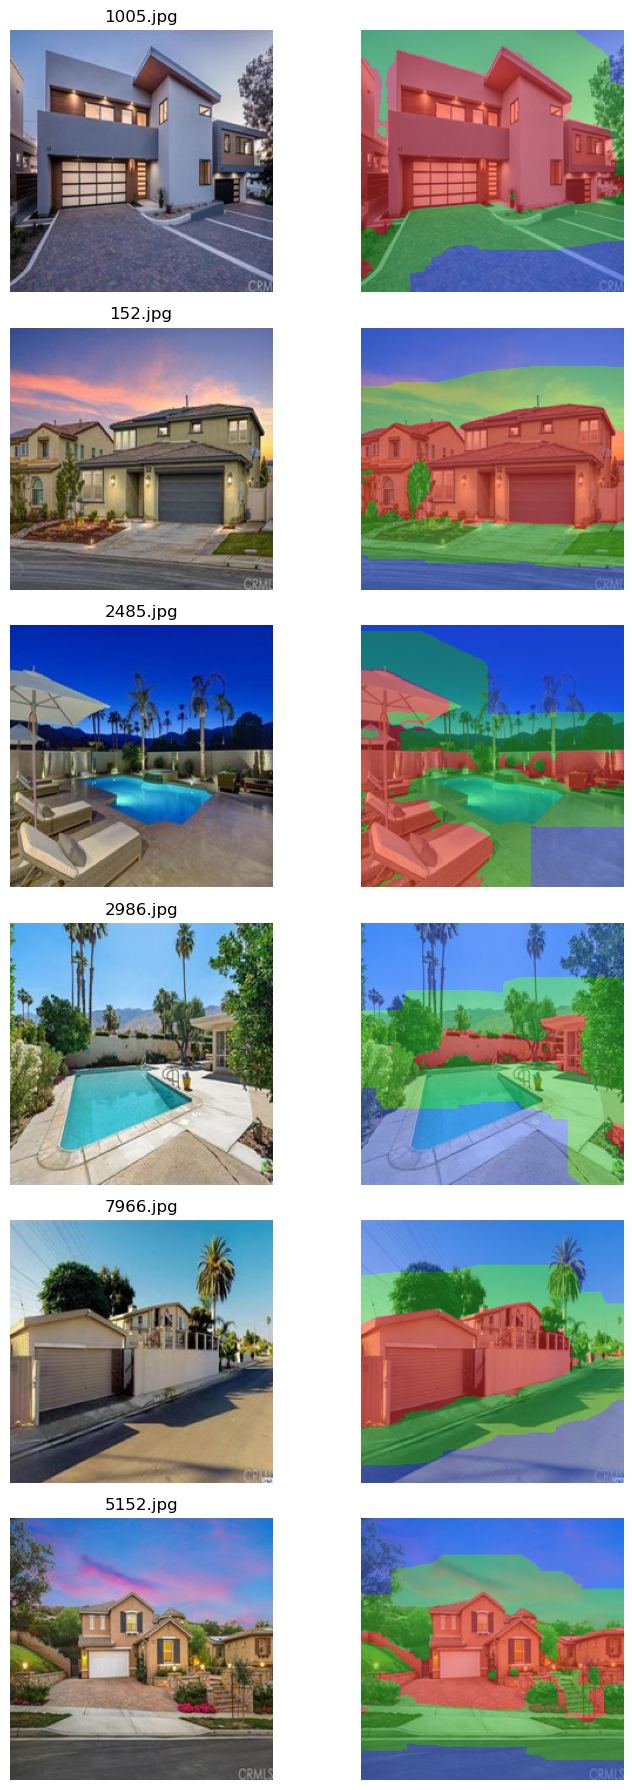

In [163]:
samples = train_split_df.sample(6, random_state=CONFIG["seed"])
fig, axes = plt.subplots(6, 2, figsize=(8, 18))

for row_index, (_, row) in enumerate(samples.iterrows()):
    image = Image.open(row[CONFIG["image_column"]]).convert("RGB").resize((224, 224))
    mask = np.load(PATHS["masks"] / f"{row[CONFIG['id_column']]}.npy")
    color = np.zeros((224, 224, 3), dtype=np.float32)
    color[mask[0] > 0.5] = (1.0, 0.2, 0.2)
    color[mask[1] > 0.5] = (0.2, 0.8, 0.2)
    color[mask[2] > 0.5] = (0.2, 0.4, 1.0)
    overlay = 0.55 * (np.asarray(image) / 255.0) + 0.45 * color
    axes[row_index, 0].imshow(image)
    axes[row_index, 1].imshow(np.clip(overlay, 0, 1))
    axes[row_index, 0].set_title(row[CONFIG["id_column"]])
    axes[row_index, 0].axis("off")
    axes[row_index, 1].axis("off")

fig.savefig(PATHS["results"] / "mask_examples.png", dpi=120, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [165]:
class HousePriceMaskDataset(HousePriceDataset):
    """Same samples as HousePriceDataset, plus a precomputed region mask."""

    def __getitem__(self, index):
        sample = super().__getitem__(index)
        mask = np.load(PATHS["masks"] / f"{sample['image_id']}.npy")
        sample["masks"] = torch.from_numpy(mask).float()
        return sample


masked_train_dataset = HousePriceMaskDataset(
    dataframe=train_split_df,
    transform=standard_train_transform,
)
masked_validation_dataset = HousePriceMaskDataset(
    dataframe=validation_df,
    transform=evaluation_transform,
)

masked_train_loader = DataLoader(
    masked_train_dataset,
    batch_size=CONFIG["batch_size"],
    shuffle=True,
    num_workers=CONFIG["num_workers"],
    pin_memory=torch.cuda.is_available(),
)
masked_validation_loader = DataLoader(
    masked_validation_dataset,
    batch_size=CONFIG["batch_size"],
    shuffle=False,
    num_workers=CONFIG["num_workers"],
    pin_memory=torch.cuda.is_available(),
)

print(f"Masked training batches:  {len(masked_train_loader)}")
print(f"Masked validation batches: {len(masked_validation_loader)}")

Masked training batches:  175
Masked validation batches: 38


In [167]:
class RegionalFusionRegressor(nn.Module):
    """Global average pooling plus three mask-guided regional vectors."""

    def __init__(self, projection_dim=128, dropout=0.30):
        super().__init__()

        vgg16 = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1)
        self.backbone = vgg16.features[:-1]

        for parameter in self.backbone.parameters():
            parameter.requires_grad = False
        for parameter in self.backbone[-7:].parameters():
            parameter.requires_grad = True

        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))
        self.region_projections = nn.ModuleList([
            nn.Sequential(
                nn.Linear(512, projection_dim),
                nn.ReLU(),
            )
            for _ in range(4)
        ])
        self.regression_head = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(projection_dim * 4 + 3, projection_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(projection_dim, 1),
        )
        
    def masked_region_pool(self, feature_maps, masks):

    # Reduce each mask to the CNN feature-map resolution.
    # Area interpolation preserves the proportion of each region.
        resized_masks = F.interpolate(
            masks.float(),
            size=feature_maps.shape[-2:],
            mode="area"
        ).clamp(0.0, 1.0)
        expanded_features = feature_maps.unsqueeze(1)
        expanded_masks = resized_masks.unsqueeze(2)
        masked_features = expanded_features * expanded_masks
        feature_sum = masked_features.sum(dim=(-2, -1))
        region_area = resized_masks.sum(
            dim=(-2, -1)
        ).unsqueeze(-1)
        
        region_area = region_area.clamp_min(1e-6)
        regional_features = feature_sum / region_area
        
        return regional_features

    def forward(self, images, masks):
        feature_maps = self.backbone(images)
        global_features = self.global_pool(feature_maps).flatten(1)

        regional = self.masked_region_pool(feature_maps, masks)
        mask_coverage = masks.float().mean(dim=(-2, -1))
        vectors = [global_features, *regional.unbind(dim=1)]
        projected = [
            layer(vector)
            for layer, vector in zip(self.region_projections, vectors)
        ]
        fused = torch.cat([*projected, mask_coverage], dim=1)
        return self.regression_head(fused).squeeze(1)

In [171]:
# Skip this cell if artifacts/checkpoints/model_e3_masked_regions.pt already exists.
CONFIG["projection_dim"] = 64
CONFIG["dropout"] = 0.50
CONFIG["learning_rate_head"] = 3e-4
CONFIG["weight_decay"] = 1e-3

set_seed(CONFIG["seed"])
model_e3 = RegionalFusionRegressor(
    projection_dim=E3_CONFIG["projection_dim"],
    dropout=E3_CONFIG["dropout"],
).to(DEVICE)

model_e3, history_e3_df, summary_e3 = fit_model(
    model=model_e3,
    train_loader=masked_train_loader,
    validation_loader=masked_validation_loader,
    experiment_config=E3_CONFIG,
    device=DEVICE
)

pd.DataFrame([summary_e3])

model_e3_refined_regional_fusion | Epoch 01/20 | MSE: 124203.9297 | RMSE: 352.4258 | MAE: 270.3004 | R²: 0.1915


model_e3_refined_regional_fusion | Epoch 02/20 | MSE: 119082.6406 | RMSE: 345.0835 | MAE: 262.8232 | R²: 0.2248


model_e3_refined_regional_fusion | Epoch 06/20 | MSE: 118664.2266 | RMSE: 344.4767 | MAE: 254.1915 | R²: 0.2276


model_e3_refined_regional_fusion | Epoch 07/20 | MSE: 120816.3750 | RMSE: 347.5865 | MAE: 257.4143 | R²: 0.2135


model_e3_refined_regional_fusion | Epoch 08/20 | MSE: 123322.7969 | RMSE: 351.1735 | MAE: 259.5415 | R²: 0.1972


,model,best_epoch,validation_loss,validation_mse,validation_rmse,validation_mae,validation_r2,checkpoint
0,model_e3_refined_regional_fusion,4,0.749819,116991.46875,342.040161,254.255081,0.238447,artifacts\checkpoints\model_e3_refined_regiona...


## 9. Evaluation and error analysis

Load the saved E3 checkpoint instead of retraining. These cells need the configuration, split, transform, `HousePriceDataset`, `fit_model`, `HousePriceMaskDataset`, and `RegionalFusionRegressor` cells. E2 is not retrained here; its validation numbers are copied from the E2 run above so every table uses the same E2 baseline.

In [114]:
def predict_prices(model, data_loader, device=DEVICE):
    """Return one row per image with the predicted price in $1000s.

    The loader must not shuffle, so rows line up with its dataframe.
    """
    model.eval()
    image_ids = []
    predictions = []

    with torch.no_grad():
        for batch in data_loader:
            outputs = forward_batch(model, batch, device)
            predictions.append(outputs.cpu())
            image_ids.extend(batch["image_id"])

    predicted = torch.cat(predictions).numpy() * TARGET_STD + TARGET_MEAN
    result = pd.DataFrame({
        CONFIG["id_column"]: image_ids,
        "prediction": np.maximum(predicted, 0),
    })

    source = data_loader.dataset.dataframe
    if CONFIG["target_column"] in source.columns:
        result[CONFIG["target_column"]] = source[CONFIG["target_column"]].to_numpy()
        result["absolute_error"] = (
            result["prediction"] - result[CONFIG["target_column"]]
        ).abs()
    return result


def regression_metrics(true_prices, predicted_prices):
    mse = mean_squared_error(true_prices, predicted_prices)
    return {
        "mse": mse,
        "rmse": np.sqrt(mse),
        "mae": mean_absolute_error(true_prices, predicted_prices),
        "r2": r2_score(true_prices, predicted_prices),
    }

In [116]:
e2_internal_test_loader = DataLoader(
    HousePriceDataset(
        dataframe=internal_test_df,
        transform=evaluation_transform
    ),
    batch_size=CONFIG["batch_size"],
    shuffle=False,
    num_workers=CONFIG["num_workers"],
    pin_memory=torch.cuda.is_available()
)

model_e2 = GlobalAveragePoolingRegressor(
    projection_dim=E2_CONFIG["projection_dim"],
    dropout=E2_CONFIG["dropout"]
).to(DEVICE)

checkpoint_e2 = torch.load(
    PATHS["checkpoints"] /
    "model_e2_global_average_pooling.pt",
    map_location=DEVICE,
    weights_only=True
)

model_e2.load_state_dict(checkpoint_e2["model_state_dict"])

e2_validation_df = predict_prices(model_e2, e2_validation_loader)

e2_internal_test_df = predict_prices(model_e2,e2_internal_test_loader)

e2_validation_df.to_csv(
    PATHS["results"] / "e2_validation_predictions.csv",
    index=False)

In [118]:
masked_internal_test_loader = DataLoader(
    HousePriceMaskDataset(
        dataframe=internal_test_df,
        transform=evaluation_transform,
    ),
    batch_size=CONFIG["batch_size"],
    shuffle=False,
    num_workers=CONFIG["num_workers"],
    pin_memory=torch.cuda.is_available(),
)

model_e3 = RegionalFusionRegressor(
    projection_dim=E3_CONFIG["projection_dim"],
    dropout=E3_CONFIG["dropout"],
).to(DEVICE)

checkpoint_e3 = torch.load(
    PATHS["checkpoints"] / "model_e3_masked_regions.pt",
    map_location=DEVICE,
    weights_only=True,
)
model_e3.load_state_dict(checkpoint_e3["model_state_dict"])

e3_validation_df = predict_prices(model_e3, masked_validation_loader)
e3_internal_test_df = predict_prices(model_e3, masked_internal_test_loader)

e3_validation_df.to_csv(
    PATHS["results"] / "e3_validation_predictions.csv",
    index=False,
)

In [120]:
price_column = CONFIG["target_column"]
metric_rows = []

for split_name, split_df in [
    ("validation", validation_df),
    ("internal_test", internal_test_df),
]:
    metric_rows.append({
        "model": "mean_baseline",
        "split": split_name,
        "source": "training-set mean price",
        **regression_metrics(
            split_df[price_column],
            np.full(len(split_df), TARGET_MEAN),
        ),
    })

for model_name, checkpoint, validation_predictions, internal_test_predictions in [
    ("e2_global_average_pooling", checkpoint_e2, e2_validation_df, e2_internal_test_df),
    ("e3_regional_fusion", checkpoint_e3, e3_validation_df, e3_internal_test_df)
]:
    for split_name, predictions_df in [
        ("validation", validation_predictions),
        ("internal_test", internal_test_predictions)
    ]:
        metric_rows.append({
            "model": model_name,
            "split": split_name,
            "source": (
                f"best validation epoch "
                f"{checkpoint['epoch']}"
            ),
            **regression_metrics(
                true_prices=predictions_df[price_column],
                predicted_prices=predictions_df["prediction"]
            )
        })

metrics_df = pd.DataFrame(metric_rows)
metrics_df.to_csv(PATHS["results"] / "metrics.csv", index=False)
metrics_df.round({"mse": 0, "rmse": 1, "mae": 1, "r2": 3})

,model,split,source,mse,rmse,mae,r2
0,mean_baseline,validation,training-set mean price,153660.0,392.0,294.4,-0.000
1,mean_baseline,internal_test,training-set mean price,162926.0,403.6,301.0,-0.000
2,e2_global_average_pooling,validation,best validation epoch 4,117960.0,343.5,259.2,0.232
3,e2_global_average_pooling,internal_test,best validation epoch 4,125681.0,354.5,263.4,0.229
4,e3_regional_fusion,validation,best validation epoch 4,116991.0,342.0,254.3,0.238
5,e3_regional_fusion,internal_test,best validation epoch 4,121994.0,349.3,256.1,0.251


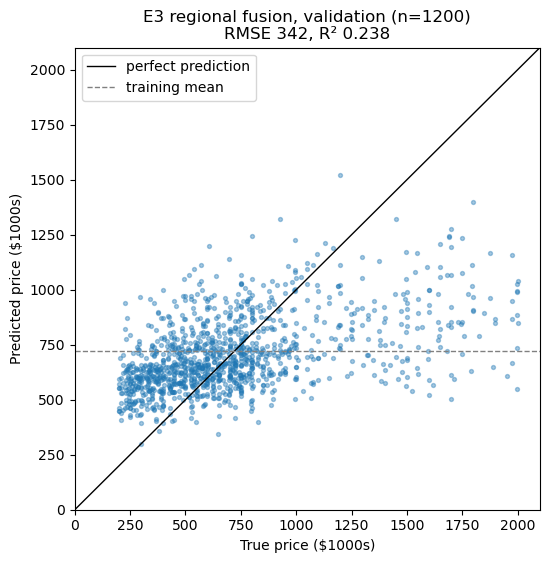

In [122]:
e3_validation_metrics = regression_metrics(
    e3_validation_df[price_column],
    e3_validation_df["prediction"],
)
limit = max(
    e3_validation_df[price_column].max(),
    e3_validation_df["prediction"].max(),
) * 1.05

fig, axis = plt.subplots(figsize=(6, 6))
axis.scatter(
    e3_validation_df[price_column],
    e3_validation_df["prediction"],
    s=8,
    alpha=0.4,
)
axis.plot([0, limit], [0, limit], color="black", linewidth=1, label="perfect prediction")
axis.axhline(TARGET_MEAN, color="grey", linestyle="--", linewidth=1, label="training mean")
axis.set_xlim(0, limit)
axis.set_ylim(0, limit)
axis.set_xlabel("True price ($1000s)")
axis.set_ylabel("Predicted price ($1000s)")
axis.set_title(
    f"E3 regional fusion, validation (n={len(e3_validation_df)})\n"
    f"RMSE {e3_validation_metrics['rmse']:.0f}, R² {e3_validation_metrics['r2']:.3f}"
)
axis.legend(loc="upper left")
fig.savefig(PATHS["results"] / "e3_pred_vs_true.png", dpi=150, bbox_inches="tight")
plt.show()

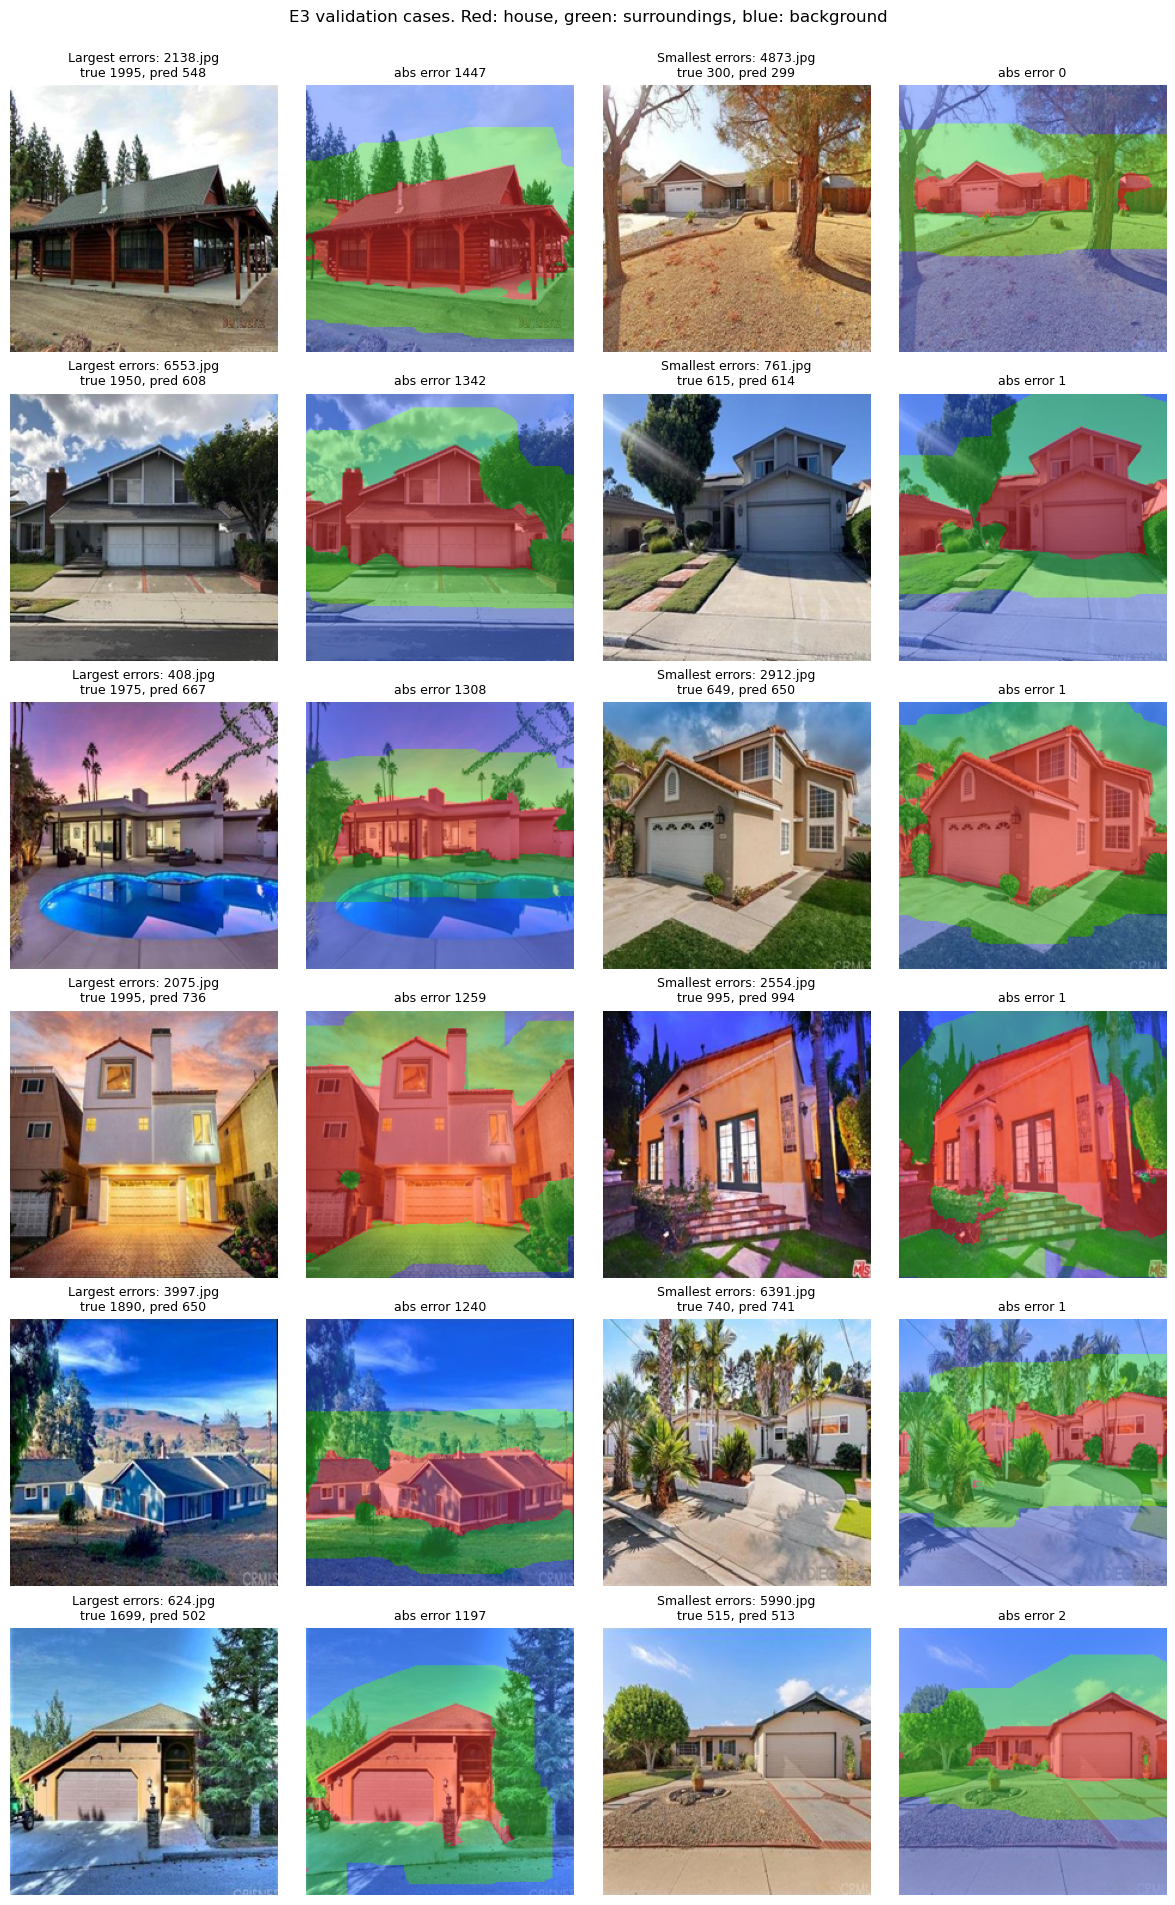

In [124]:
def mask_overlay(image_id, image_path):
    image = Image.open(image_path).convert("RGB").resize((224, 224))
    mask = np.load(PATHS["masks"] / f"{image_id}.npy")
    color = np.zeros((224, 224, 3), dtype=np.float32)
    color[mask[0] > 0.5] = (1.0, 0.2, 0.2)
    color[mask[1] > 0.5] = (0.2, 0.8, 0.2)
    color[mask[2] > 0.5] = (0.2, 0.4, 1.0)
    overlay = 0.55 * (np.asarray(image) / 255.0) + 0.45 * color
    return image, np.clip(overlay, 0, 1)


ranked = e3_validation_df.merge(
    validation_df[[CONFIG["id_column"], CONFIG["image_column"]]],
    on=CONFIG["id_column"],
).sort_values("absolute_error")
case_groups = [
    ("Largest errors", ranked.tail(6).iloc[::-1]),
    ("Smallest errors", ranked.head(6)),
]

fig, axes = plt.subplots(6, 4, figsize=(12, 19))
for group_index, (group_name, cases) in enumerate(case_groups):
    for row_index, (_, row) in enumerate(cases.iterrows()):
        image, overlay = mask_overlay(row[CONFIG["id_column"]], row[CONFIG["image_column"]])
        image_axis = axes[row_index, group_index * 2]
        overlay_axis = axes[row_index, group_index * 2 + 1]
        image_axis.imshow(image)
        overlay_axis.imshow(overlay)
        image_axis.set_title(
            f"{group_name}: {row[CONFIG['id_column']]}\n"
            f"true {row[price_column]:.0f}, pred {row['prediction']:.0f}",
            fontsize=9,
        )
        overlay_axis.set_title(f"abs error {row['absolute_error']:.0f}", fontsize=9)
        image_axis.axis("off")
        overlay_axis.axis("off")

fig.suptitle("E3 validation cases. Red: house, green: surroundings, blue: background", y=1.0)
plt.tight_layout()
fig.savefig(PATHS["results"] / "e3_error_cases.png", dpi=120, bbox_inches="tight")
plt.show()

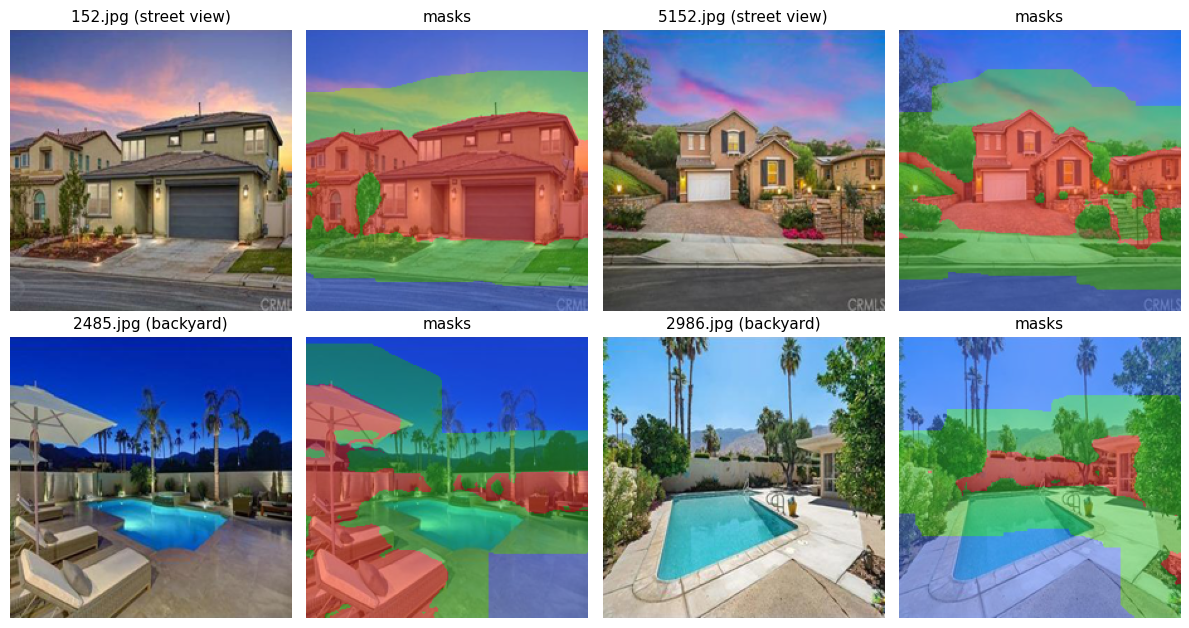

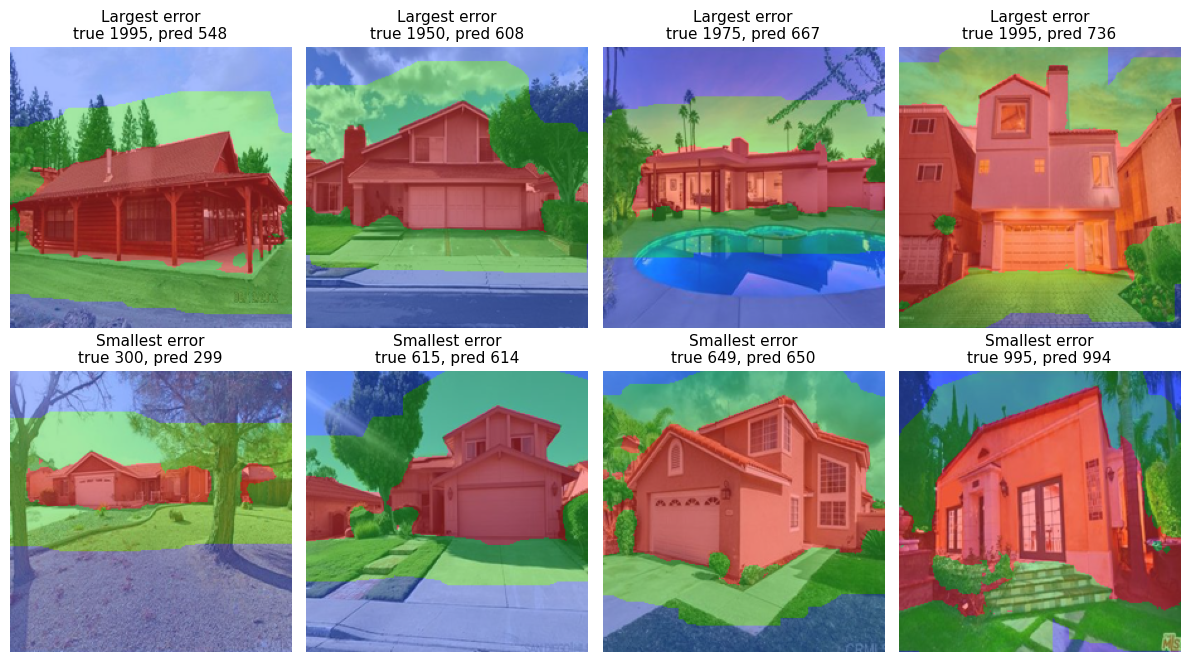

In [126]:
# Two-row versions of the mask and error-case figures, sized for a two-column IEEE page.
path_by_id = train_df.set_index(CONFIG["id_column"])[CONFIG["image_column"]]
mask_figure_cases = [
    ("152.jpg", "street view"),
    ("5152.jpg", "street view"),
    ("2485.jpg", "backyard"),
    ("2986.jpg", "backyard"),
]

fig, axes = plt.subplots(2, 4, figsize=(12, 6.4))
for case_index, (image_id, label) in enumerate(mask_figure_cases):
    image, overlay = mask_overlay(image_id, path_by_id[image_id])
    row, column = divmod(case_index, 2)
    axes[row, column * 2].imshow(image)
    axes[row, column * 2 + 1].imshow(overlay)
    axes[row, column * 2].set_title(f"{image_id} ({label})", fontsize=11)
    axes[row, column * 2 + 1].set_title("masks", fontsize=11)
for axis in axes.flat:
    axis.axis("off")
plt.tight_layout()
fig.savefig(PATHS["results"] / "mask_examples_compact.png", dpi=200, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(2, 4, figsize=(12, 6.8))
for row, (group_name, cases) in enumerate([
    ("Largest error", ranked.tail(4).iloc[::-1]),
    ("Smallest error", ranked.head(4)),
]):
    for column, (_, case) in enumerate(cases.iterrows()):
        _, overlay = mask_overlay(case[CONFIG["id_column"]], case[CONFIG["image_column"]])
        axes[row, column].imshow(overlay)
        axes[row, column].set_title(
            f"{group_name}\ntrue {case[price_column]:.0f}, pred {case['prediction']:.0f}",
            fontsize=11,
        )
        axes[row, column].axis("off")
plt.tight_layout()
fig.savefig(PATHS["results"] / "e3_error_cases_compact.png", dpi=200, bbox_inches="tight")
plt.show()

In [128]:
analysis_df = e3_validation_df.copy()
analysis_df["signed_error"] = analysis_df["prediction"] - analysis_df[price_column]
analysis_df["house_fraction"] = [
    float(np.load(PATHS["masks"] / f"{image_id}.npy")[0].mean())
    for image_id in analysis_df[CONFIG["id_column"]]
]

analysis_df["price_quintile"] = pd.qcut(
    analysis_df[price_column], 5,
    labels=["Q1 cheapest", "Q2", "Q3", "Q4", "Q5 most expensive"],
)
analysis_df["house_coverage"] = pd.cut(
    analysis_df["house_fraction"],
    bins=[-0.01, 0.10, 0.30, 0.50, 1.0],
    labels=["under 10%", "10-30%", "30-50%", "over 50%"],
)

def summarise(grouping):
    return analysis_df.groupby(grouping, observed=True).agg(
        images=("absolute_error", "size"),
        mean_true_price=(price_column, "mean"),
        mean_prediction=("prediction", "mean"),
        mean_signed_error=("signed_error", "mean"),
        mae=("absolute_error", "mean"),
    ).round(1)


by_price = summarise("price_quintile")
by_coverage = summarise("house_coverage")
by_price.to_csv(PATHS["results"] / "e3_error_by_price.csv")
by_coverage.to_csv(PATHS["results"] / "e3_error_by_house_coverage.csv")

print("Prediction spread: std of predictions", round(analysis_df["prediction"].std(), 1),
      "vs std of true prices", round(analysis_df[price_column].std(), 1))
display(by_price)
display(by_coverage)

Prediction spread: std of predictions 167.5 vs std of true prices 392.1


,images,mean_true_price,mean_prediction,mean_signed_error,mae
price_quintile,,,,,
Q1 cheapest,240,302.1,594.799988,292.7,292.9
Q2,243,478.6,661.599976,183.0,189.0
Q3,238,635.6,690.900024,55.4,115.6
Q4,240,803.3,730.500000,-72.8,144.2
Q5 most expensive,239,1363.8,845.599976,-518.1,530.4


,images,mean_true_price,mean_prediction,mean_signed_error,mae
house_coverage,,,,,
under 10%,92,835.3,797.299988,-38.1,312.2
10-30%,670,707.4,693.400024,-14.0,253.8
30-50%,324,702.2,698.200012,-4.0,241.7
over 50%,114,705.8,712.700012,6.9,245.8
